In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.append("../..")

from src.data_processing.load_data import ClimateModelData, ClimateReanalysisData
from src.utils.utils_xarray import (
    get_time_resolution,
    match_time_steps,
    match_time_steps_interpolate,
    get_time_offset,
    get_specific_hourly_data
)

import json
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import seaborn as sns
import xarray as xr

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


# Load data

In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"

path_energy_ch = path_data_processed / "energy" / "ch"

path_figs = Path(paths["path_figs"])

In [4]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

institute = climate_model_chain.split("-")[0]
rcm = climate_model_chain.split("_")[0]
gcm = climate_model_chain.split("_")[1]
ensemble = climate_model_chain.split("_")[-1]

In [5]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
extent_ch = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}

In [6]:
regridded_cerra_var_path = path_data_processed / "cerra_processed" / "regridded"

chunks = {"time": -1, "lat": 20, "lon": 20}

ds_ssrd = ClimateReanalysisData(
    path_data_processed
    / "cerra_processed"
    / "regridded"
    / "ssrd.zarr",
    chunks=chunks,
    extent=extent_ch,
    load=False,
    drop_leap_days=False
)

time_res = get_time_resolution(ds_ssrd.ds_data).total_seconds()
ds_ssrd.ds_data = ds_ssrd.ds_data / time_res
ds_ssrd.ds_data["ssrd"].attrs["units"] = "W m**-2"

ds_rsds = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
    / "3hr"
    / "rsds.zarr",
    extent=extent_ch,
)

ds_rsds_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "rsds.zarr",
    extent=extent_ch,
)

ds_tas_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "tas.zarr",
    extent=extent_ch,
)

ds_sfcWind_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
    / "3hr"
    / "sfcWind.zarr",
    extent=extent_ch,
)

In [7]:
most_common_offset_between = get_time_offset(
    ds_rsds.ds_data, ds_ssrd.ds_data
)
if most_common_offset_between != pd.Timedelta('0 days 00:00:00'):
    # Subtract 1 hour and 30 minutes from all timesteps using a time offset
    ds_ssrd.ds_data = ds_ssrd.ds_data.assign_coords(
        time=ds_ssrd.ds_data.time - most_common_offset_between
    )

# Remove leap days from the reanalysis dataset
ds_ssrd.ds_data = ds_ssrd.ds_data.sel(
    time=~(
        (ds_ssrd.ds_data.time.dt.month == 2) & (ds_ssrd.ds_data.time.dt.day == 29)
    )
)

Is there an offset? True


In [8]:
ds_ssrd_22 = set(get_specific_hourly_data(ds_ssrd.ds_data.sel(time=slice("1991", "2020")), 22).time.values)
ds_rsds_22 = set(get_specific_hourly_data(ds_rsds.ds_data.sel(time=slice("1991", "2020")), 22).time.values)

ds_ssrd_unique_times = ds_ssrd_22.difference(ds_rsds_22)
ds_rsds_unique_times = ds_rsds_22.difference(ds_ssrd_22)

print("Timesteps unique to ds_ssrd:", ds_ssrd_unique_times)
print("Timesteps unique to ds_rsds:", ds_rsds_unique_times)

Timesteps unique to ds_ssrd: set()
Timesteps unique to ds_rsds: set()


In [42]:
import pvlib

def distribute_3hr_to_hourly(ghi_3hr, time_3hr, lat, lon, timezone='UTC'):
    # Create 3 hourly points per 3-hour block
    start_time = pd.to_datetime(time_3hr[0]).replace(
            hour=0, minute=0
        )
    end_time = pd.to_datetime(time_3hr[-1]).replace(
            hour=23, minute=0
        )
    time_hourly = pd.date_range(
        start=start_time,
        end=end_time,
        freq='H',
        tz=timezone
    )

    # Get solar position and cos(zenith)
    solpos = pvlib.solarposition.get_solarposition(time_hourly, lat, lon)
    cosz = np.cos(np.radians(solpos['zenith'].values))
    cosz[cosz < 0] = 0  # Nighttime = 0

    # Distribute each 3-hour value to 3 hourly values
    result = np.zeros_like(cosz)
    for i, t_start in enumerate(time_3hr):
        block_idx = slice(i * 3, (i + 1) * 3)
        weights = cosz[block_idx]
        if weights.sum() > 0:
            weights = weights / weights.sum()
        result[block_idx] = ghi_3hr[i] * weights
    return result


def interpolate_ds_to_hourly(ds_3hr, timezone='UTC'):
    # Broadcast lat/lon so each gridpoint has coordinates
    lat_vals = ds_3hr['lat']
    lon_vals = ds_3hr['lon']
    time_3hr = ds_3hr['time'].values

    # Create 3 hourly points per 3-hour block
    start_time = pd.to_datetime(time_3hr[0]).replace(
            hour=0, minute=0
        )
    end_time = pd.to_datetime(time_3hr[-1]).replace(
            hour=23, minute=0
        )
    time_hourly = pd.date_range(
        start=start_time,
        end=end_time,
        freq='h',
        tz=timezone
    )

    def wrapped_func(ghi_3hr, lat, lon):
        return distribute_3hr_to_hourly(ghi_3hr, time_3hr, float(lat), float(lon), timezone)

    # Apply ufunc over lat/lon (parallelizable)
    ds_hourly = xr.apply_ufunc(
        wrapped_func,
        ds_3hr,
        lat_vals,
        lon_vals,
        input_core_dims=[["time"], [], []],
        output_core_dims=[["time"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[ds_3hr.dtype]
    )

    # Assign the new time coordinate
    ds_hourly = ds_hourly.assign_coords(time=("time", time_hourly))
    ds_hourly.name = ds_3hr.name + "_hourly"
    return ds_hourly


In [32]:
time_3hr = ds_ssrd.ds_data.sel(time="2020").ssrd.time.values
lat = ds_ssrd.ds_data.lat[0].item()
lon = ds_ssrd.ds_data.lon[0].item()
# Create 3 hourly points per 3-hour block
start_time = pd.to_datetime(time_3hr[0]).replace(
        hour=0, minute=0
    )
end_time = pd.to_datetime(time_3hr[-1]).replace(
        hour=23, minute=0
    )
time_hourly = pd.date_range(
    start=start_time,
    end=end_time,
    freq='h',
    tz="UTC"
)

# Get solar position and cos(zenith)
solpos = pvlib.solarposition.get_solarposition(time_hourly, lat, lon)
cosz = np.cos(np.radians(solpos['zenith'].values))
cosz[cosz < 0] = 0  # Nighttime = 0
cosz

array([0., 0., 0., ..., 0., 0., 0.])

In [36]:
ghi_3hr = ds_ssrd.ds_data.sel(time="2020").ssrd.isel(lat=0, lon=0).values

In [40]:
i = 4
block_idx = slice(i * 3, (i + 1) * 3)
weights = cosz[block_idx]
block_idx, weights

(slice(12, 15, None), array([0.3578973 , 0.32140674, 0.24391497]))

In [ ]:
ghi_hourly = distribute_3hr_to_hourly(ds_ssrd.ds_data.sel(time="2020").ssrd.isel(lat=0, lon=0).values, ds_ssrd.ds_data.sel(time="2020").ssrd.time.values, ds_ssrd.ds_data.lat[0].item(), ds_ssrd.ds_data.lon[0].item(), timezone='UTC')

array([[0.],
       [0.],
       [0.],
       ...,
       [0.],
       [0.],
       [0.]])

In [ ]:
interpolate_ds_to_hourly()

In [12]:
ds_rsds_bc_subset = ds_rsds_bc.ds_data.load()
ds_rsds_subset = ds_rsds.ds_data.load()
ds_ssrd_subset = ds_ssrd.ds_data.load()
# ds_ssrd_era5_subset = ds_ssrd_era5_subset.load()

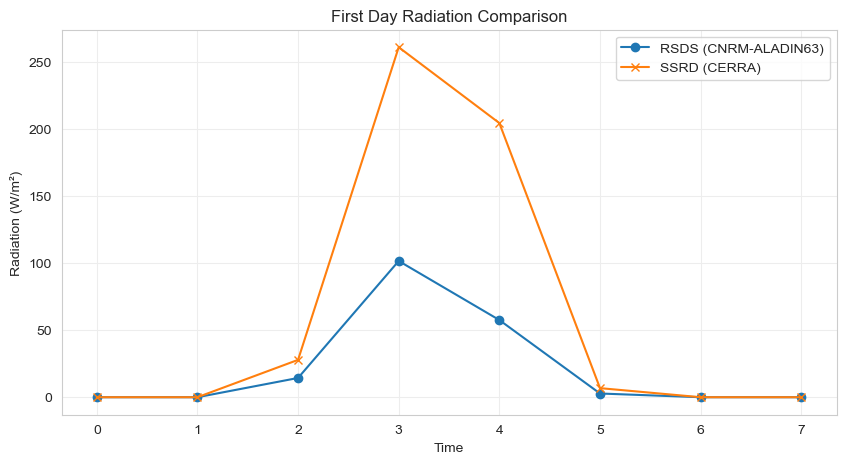

In [19]:
# Extract the first day for the first lat/lon as numpy arrays
# Extract the first day for the first lat/lon
first_day_rsds = ds_rsds_subset.isel(lat=0, lon=0).sel(time=slice("1991-01-01", "1991-01-01"))
first_day_ssrd = ds_ssrd_subset.isel(lat=0, lon=0).sel(time=slice("1991-01-01", "1992-01-01"))

first_day_rsds_values = first_day_rsds.rsds.values
first_day_ssrd_values = first_day_ssrd.ssrd.values[1:9]
time_values = pd.to_datetime(first_day_rsds.time.values)

# Plot the data
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(np.arange(0, 8), first_day_rsds_values, label="RSDS (CNRM-ALADIN63)", marker='o')
ax.plot(np.arange(0, 8), first_day_ssrd_values, label="SSRD (CERRA)", marker='x')
ax.set_title("First Day Radiation Comparison")
ax.set_ylabel("Radiation (W/m²)")
ax.set_xlabel("Time")
ax.legend()
plt.show()

In [ ]:
first_time_step = ds_rsds.ds_data.time[0].dt
if first_time_step.hour == 1 and first_time_step.minute == 30:
    print()
    ds_ssrd_subset.time - pd.Timedelta(hours=1, minutes=30)

In [29]:
from collections import Counter

# Compute time differences between ds_rsds and ds_ssrd
# Filter the time values for the year 1991
rsds_time_1991 = ds_rsds.ds_data.time.sel(time=slice("1991-01-01", "1991-12-31"))
ssrd_time_1991 = ds_ssrd.ds_data.time.sel(time=slice("1991-01-01", "1991-12-31"))

# Compute time differences between the two datasets for the year 1991
time_diffs_between = pd.to_timedelta(
    rsds_time_1991.values - ssrd_time_1991.values[:len(rsds_time_1991)]
)
most_common_offset_between = Counter(time_diffs_between).most_common(1)[0][0]

print(f"Most common time offset between ds_rsds and ds_ssrd: {most_common_offset_between}")


Most common time offset between ds_rsds and ds_ssrd: 0 days 01:30:00


In [30]:
has_offset = most_common_offset_between != pd.Timedelta('0 days 00:00:00')
print(f"Is there an offset? {has_offset}")

Is there an offset? True


## Get hourly values

In [ ]:
ds_rsds_subset.isel(time=slice(0, 8), lat=0, lon=0)


<xarray.Dataset> Size: 112B
Dimensions:  (time: 8)
Coordinates:
    lat      float64 8B 45.85
    lon      float64 8B 5.95
  * time     (time) datetime64[ns] 64B 1991-01-01T01:30:00 ... 1991-01-01T22:...
Data variables:
    rsds     (time) float32 32B 0.0 0.0 14.38 101.7 57.6 2.774 0.0 0.0
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/f1f9c0be-0335-4309-9a2f-273d...

In [ ]:
import numpy as np

def solar_declination(day_of_year):
    # Declination angle in radians
    return np.radians(23.44) * np.sin(np.radians(360 / 365 * (day_of_year - 81)))

def hour_angle(hour):
    # Hour angle in radians. Solar noon = 0, each hour = 15° = π/12 radians
    return np.radians(15 * (hour - 12))

def cos_zenith_angle(lat_rad, decl_rad, h_angle):
    # cos(Z) = sin(φ)sin(δ) + cos(φ)cos(δ)cos(h)
    return np.maximum(0, np.sin(lat_rad) * np.sin(decl_rad) + np.cos(lat_rad) * np.cos(decl_rad) * np.cos(h_angle))

def estimate_hourly_radiation(lat_deg, day_of_year, radiation_3h_means):
    lat_rad = np.radians(lat_deg)
    decl = solar_declination(day_of_year)

    hourly_cosz = []
    for hour in range(24):
        h = hour_angle(hour)
        cz = cos_zenith_angle(lat_rad, decl, h)
        hourly_cosz.append(cz)

    hourly_cosz = np.array(hourly_cosz)
    hourly_radiation = np.zeros(24)

    # Scale cosine-based shape within each 3-hour block
    for i in range(8):  # 8 blocks of 3 hours
        idx = slice(i * 3, (i + 1) * 3)
        block_cosz = hourly_cosz[idx]
        if block_cosz.sum() == 0:
            scaled = np.zeros(3)
        else:
            scale = radiation_3h_means[i] / block_cosz.mean()
            scaled = block_cosz * scale
        hourly_radiation[idx] = scaled

    return hourly_radiation



In [12]:
import numpy as np
import xarray as xr

def solar_declination(day_of_year):
    return np.radians(23.44) * np.sin(np.radians(360 / 365 * (day_of_year - 81)))

def hour_angle(hour_decimal):
    return np.radians(15 * (hour_decimal - 12))

def cos_zenith(lat_rad, decl_rad, h_angle):
    return np.sin(lat_rad) * np.sin(decl_rad) + np.cos(lat_rad) * np.cos(decl_rad) * np.cos(h_angle)

def expand_to_half_hourly_cosine(ds_3hr, lat_name='lat', lon_name='lon', time_name='time'):
    """
    Convert 3-hourly downwelling shortwave radiation (W/m²) to half-hourly,
    using cosine zenith angle weighting. Nighttime (sun below horizon) values are set to zero.
    """
    lats = ds_3hr[lat_name]
    times_3hr = ds_3hr[time_name]
    day_of_year = times_3hr.dt.dayofyear

    # Half-hour offsets for each 3-hour block
    half_hour_offsets = np.arange(0, 3, 0.5)
    times_half_hour = []
    for t in times_3hr.values:
        for h in half_hour_offsets:
            times_half_hour.append(np.datetime64(t) + np.timedelta64(int(h * 60), 'm'))
    times_half_hour = xr.DataArray(times_half_hour, dims='time')

    lat_rad = np.deg2rad(lats)
    decl_rad = solar_declination(day_of_year)

    hour_angles = hour_angle(half_hour_offsets + 0.25)  # Midpoints of each 30-min slot

    half_hourly_list = []

    # Precompute cosine values for normalization
    block_cosz_all = []
    for h_ang in hour_angles:
        cz = cos_zenith(lat_rad[None, :], decl_rad[:, None], h_ang)  # (time, lat)
        cz = np.maximum(0, cz)  # zero out night
        block_cosz_all.append(cz)
    block_cosz_all = np.stack(block_cosz_all, axis=0)  # (6, time, lat)

    mean_cosz = np.mean(block_cosz_all, axis=0)  # (time, lat)
    scale = ds_3hr / mean_cosz  # (time, lat, lon)

    # Now compute scaled half-hour values
    for cz in block_cosz_all:
        scaled = scale * cz[:, :, None]  # (time, lat, lon)
        half_hourly_list.append(scaled)

    # Stack and assign time
    half_hourly_out = xr.concat(half_hourly_list, dim='time')
    half_hourly_out = half_hourly_out.assign_coords(time=times_half_hour)
    half_hourly_out = half_hourly_out.fillna(0)
    half_hourly_out.name = ds_3hr.name + '_half_hourly'

    return half_hourly_out

ds_rsds_half_hourly = expand_to_half_hourly_cosine(ds_rsds_subset.isel(time=slice(0, 8), lat=0, lon=0))

IndexError: too many indices

In [8]:
first_time_step = pd.to_datetime(ds_rsds_bc_subset.time.values[0])
start_date = pd.to_datetime(ds_ssrd_subset.time.values[0]).replace(
    hour=first_time_step.hour, minute=first_time_step.minute
)
time_range = pd.date_range(
    start=start_date,
    end=pd.to_datetime(ds_rsds_bc_subset.time.max().item()),
    freq="h",
)
skip_leap_days = True
if skip_leap_days:
    # Remove leap days from the time range
    time_range = time_range[~((time_range.month == 2) & (time_range.day == 29))]

# Step 2: Interpolate ds_rsds_bc_subset to the new hourly time index
# Step 3: Fill NaN values at the beginning and at the end of the time series
ds_ssrd_hourly = (
    ds_ssrd_subset.interp(time=time_range).bfill(dim="time").ffill(dim="time")
)

In [9]:
ds_ssrd_time_aligned = match_time_steps_interpolate(ds_rsds_bc_subset, ds_ssrd_subset)

Adjusting time steps of the reference dataset


In [10]:
ds_rsds_bc_subset_hourly_mean = ds_rsds_bc_subset.groupby("time.hour").mean(dim="time")
ds_ssrd_subset_hourly_mean = ds_ssrd_subset.groupby("time.hour").mean(dim="time")
ds_rsds_subset_hourly_mean = ds_rsds_subset.groupby("time.hour").mean(dim="time")
ds_ssrd_hourly_mean = ds_ssrd_hourly.groupby("time.hour").mean(dim="time")
# ds_ssrd_era5_subset_hourly_mean = ds_ssrd_era5_subset.groupby("time.hour").mean(dim="time")

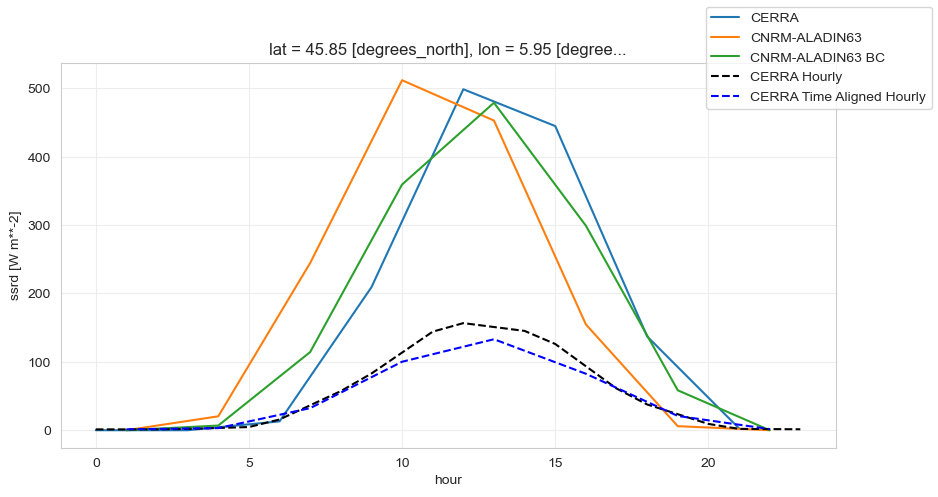

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
lat, lon = 0, 0
ds_ssrd_subset_hourly_mean.isel(lat=lat, lon=lon).ssrd.plot(ax=ax, label="CERRA")
ds_rsds_subset_hourly_mean.isel(lat=lat, lon=lon).rsds.plot(ax=ax, label="CNRM-ALADIN63")
ds_rsds_bc_subset_hourly_mean.isel(lat=lat, lon=lon).rsds.plot(ax=ax, label="CNRM-ALADIN63 BC")
ds_ssrd_hourly_mean.isel(lat=lat, lon=lon).ssrd.plot(ax=ax, label="CERRA Hourly", color="black", linestyle="--")
# ds_ssrd_era5_subset_hourly_mean.isel(latitude=lat, longitude=lon).ssrd.plot(ax=ax, label="ERA5-Land Hourly", color="red", linestyle="--")
fig.legend()

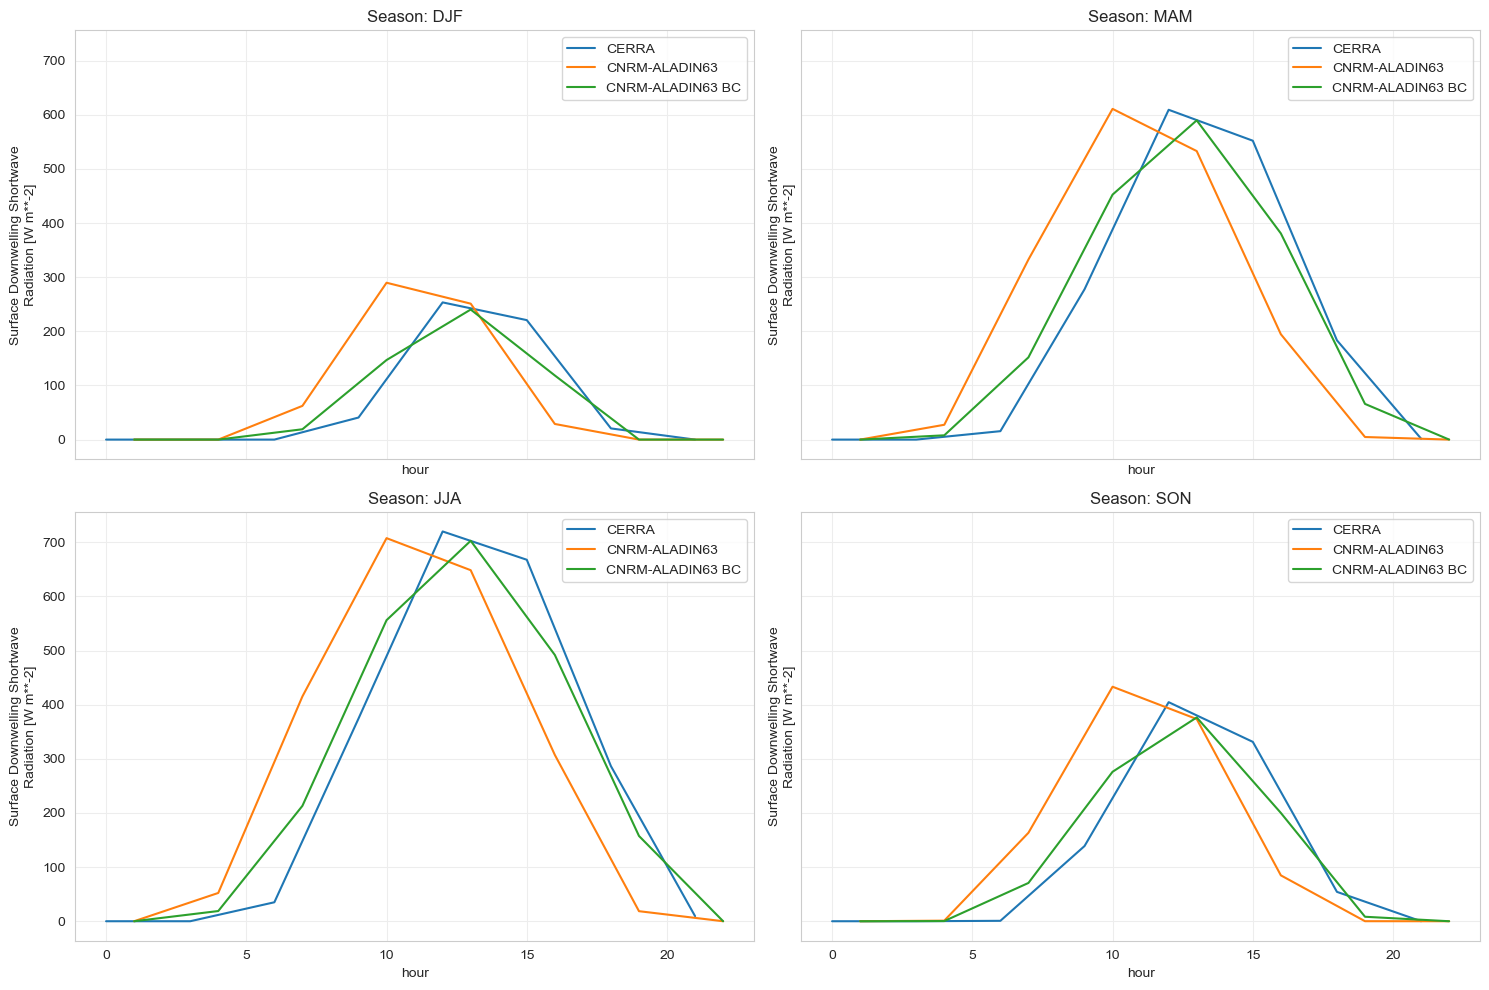

In [93]:
# Define a function to filter data for a specific season
def filter_season(data, season):
    if season == "DJF":
        return data.where((data["time.month"] == 12) | (data["time.month"] == 1) | (data["time.month"] == 2), drop=True)
    elif season == "MAM":
        return data.where((data["time.month"] == 3) | (data["time.month"] == 4) | (data["time.month"] == 5), drop=True)
    elif season == "JJA":
        return data.where((data["time.month"] == 6) | (data["time.month"] == 7) | (data["time.month"] == 8), drop=True)
    elif season == "SON":
        return data.where((data["time.month"] == 9) | (data["time.month"] == 10) | (data["time.month"] == 11), drop=True)

# Calculate seasonal hourly means manually
seasons = ["DJF", "MAM", "JJA", "SON"]
seasonal_means = {}
for season in seasons:
    seasonal_means[season] = {
        "ssrd": filter_season(ds_ssrd_subset, season).groupby("time.hour").mean(dim="time"),
        "rsds": filter_season(ds_rsds_subset, season).groupby("time.hour").mean(dim="time"),
        "rsds_bc": filter_season(ds_rsds_bc_subset, season).groupby("time.hour").mean(dim="time"),
    }

# Plot seasonal variations
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=True)
for ax, season in zip(axes.flatten(), seasons):
    seasonal_means[season]["ssrd"].isel(lat=lat, lon=lon).ssrd.plot(ax=ax, label="CERRA")
    seasonal_means[season]["rsds"].isel(lat=lat, lon=lon).rsds.plot(ax=ax, label="CNRM-ALADIN63")
    seasonal_means[season]["rsds_bc"].isel(lat=lat, lon=lon).rsds.plot(ax=ax, label="CNRM-ALADIN63 BC")
    ax.set_title(f"Season: {season}")
    ax.legend()
fig.tight_layout()


In [73]:
from scipy.interpolate import CubicSpline
spline_rsds = CubicSpline(np.arange(len(ds_rsds_subset.isel(lat=0, lon=0).time)), ds_rsds_subset.rsds.isel(lat=0, lon=0))
spline_ssrd = CubicSpline(np.arange(len(ds_ssrd_subset.isel(lat=0, lon=0).time)), ds_ssrd_subset.ssrd.isel(lat=0, lon=0))

In [74]:
first_time_step_rsds = pd.to_datetime(ds_rsds_subset.time.values[0]).replace(
    hour=0, minute=0
)
first_time_step_ssrd = pd.to_datetime(ds_ssrd_subset.time.values[0]).replace(
    hour=0, minute=0
)
last_time_step_rsds = pd.to_datetime(ds_rsds_subset.time.values[-1]).replace(
    hour=23, minute=0
)
last_time_step_ssrd = pd.to_datetime(ds_ssrd_subset.time.values[-1]).replace(
    hour=23, minute=0
)
time_range_rsds = pd.date_range(
    start=first_time_step_rsds,
    end=last_time_step_rsds,
    freq="h",
)

time_range_ssrd = pd.date_range(
    start=first_time_step_ssrd,
    end=last_time_step_ssrd,
    freq="h",
)

time_range_rsds_numeric = (time_range_rsds - time_range_rsds[0]) / np.timedelta64(1, "h")
time_range_ssrd_numeric = (time_range_ssrd - time_range_ssrd[0]) / np.timedelta64(1, "h")

spline_rsds_hourly = np.clip(spline_rsds(time_range_rsds_numeric), 0, None)
spline_ssrd_hourly = np.clip(spline_ssrd(time_range_ssrd_numeric), 0, None)

In [75]:
spline_rsds_hourly.shape, spline_ssrd_hourly.shape

((955488,), (319944,))

In [76]:
ds_spline_rsds_hourly = xr.DataArray(
    data=spline_rsds_hourly,
    coords={"time": time_range_rsds},
    dims=["time"],
    name="rsds"
)

ds_spline_ssrd_hourly = xr.DataArray(
    data=spline_ssrd_hourly,
    coords={"time": time_range_ssrd},
    dims=["time"],
    name="ssrd"
)

In [77]:
# ds_spline_rsds_hourly = xr.Dataset(
#     coords={
#         "time": time_range_rsds,
#         "lat": ds_rsds_subset.lat,
#         "lon": ds_rsds_subset.lon,
#     },
#     data_vars={
#         "rsds": (["time", "lat", "lon"], spline_rsds_hourly),
#     },
# )


# ds_spline_ssrd_hourly = xr.Dataset(
#     coords={
#         "time": time_range_ssrd,
#         "lat": ds_ssrd_subset.lat,
#         "lon": ds_ssrd_subset.lon,
#     },
#     data_vars={
#         "ssrd": (["time", "lat", "lon"], spline_ssrd_hourly),
#     },
# )

In [78]:
ds_spline_rsds_hourly_mean = ds_spline_rsds_hourly.groupby("time.hour").mean(dim="time")
ds_spline_ssrd_hourly_mean = ds_spline_ssrd_hourly.groupby("time.hour").mean(dim="time")

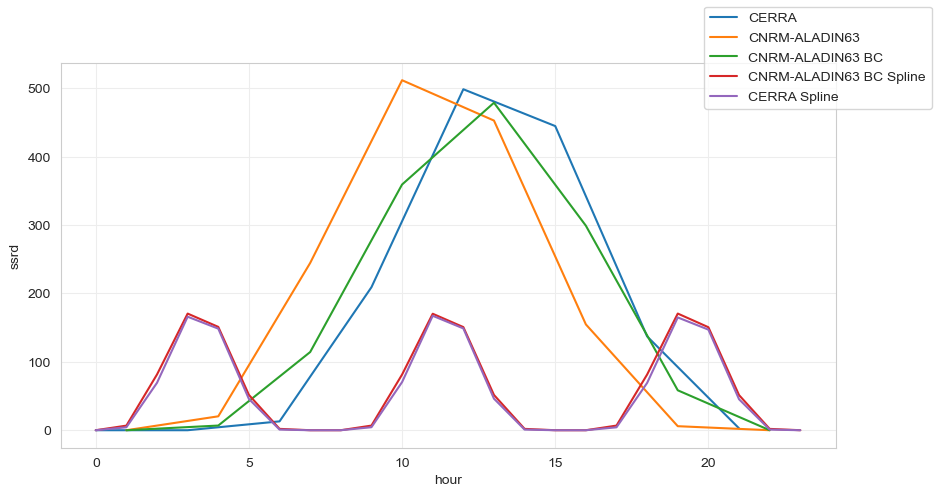

In [79]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ds_ssrd_subset_hourly_mean.isel(lat=0, lon=0).ssrd.plot(ax=ax, label="CERRA")
ds_rsds_subset_hourly_mean.isel(lat=0, lon=0).rsds.plot(ax=ax, label="CNRM-ALADIN63")
ds_rsds_bc_subset_hourly_mean.isel(lat=0, lon=0).rsds.plot(ax=ax, label="CNRM-ALADIN63 BC")
ds_spline_rsds_hourly_mean.plot(ax=ax, label="CNRM-ALADIN63 BC Spline")
ds_spline_ssrd_hourly_mean.plot(ax=ax, label="CERRA Spline")
fig.legend()